# Banka Pazarlama MLOps Projesi

Bu projede UCI Bank Marketing veri seti kullanılarak bir müşterinin vadeli mevduat açıp açmayacağı tahmin edilmektedir.
Verideki dengesizlik (imbalance) ele alınmış, pipeline oluşturulmuş ve en iyi model kaydedilmiştir.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, f1_score, precision_recall_curve, roc_curve
import joblib

import warnings
warnings.filterwarnings('ignore')

C:\Users\silak\.matplotlib is not a writable directory


Matplotlib created a temporary cache directory at C:\Users\silak\AppData\Local\Temp\matplotlib-ddk0v6k8 because there was an issue with the default path (C:\Users\silak\.matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


## 1. Veri Yükleme

In [2]:
# Veri noktalı virgül ile ayrılmış
url = 'https://raw.githubusercontent.com/mustafagurbuz06/mlops-workflow/main/data/bank-additional-full.csv'
df = pd.read_csv(url, sep=';')
print('Veri boyutu:', df.shape)
df.head()

Veri boyutu: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 2. Sınıf Dengesizliği (EDA)

y
no     36548
yes     4640
Name: count, dtype: int64
Abone olma oranı: % 11.27


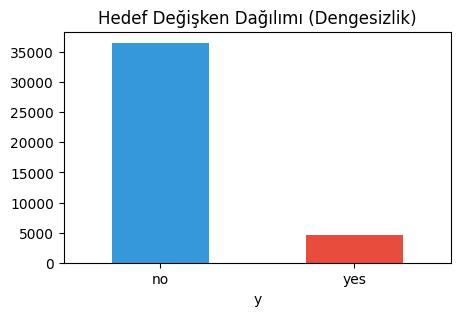

In [3]:
# Hedef değişken dağılımı
print(df['y'].value_counts())
print('Abone olma oranı: %', round((df['y'] == 'yes').mean() * 100, 2))

# Grafik
df['y'].value_counts().plot(kind='bar', color=['#3498db', '#e74c3c'], figsize=(5, 3))
plt.title('Hedef Değişken Dağılımı (Dengesizlik)')
plt.xticks(rotation=0)
plt.show()

Burada önemli bir nokta var: Müşterilerin yaklaşık %89'u 'no', sadece %11'i 'yes'.
Dolayısıyla sıradan accuracy metriği yerine ROC-AUC ve F1-Score metriklerine bakmalıyız.

## 3. Özellik Mühendisliği ve Pipeline Hazırlığı

In [4]:
df_model = df.copy()

# pdays 999 değeri daha önce hiç aranmamış demek
df_model['was_contacted'] = (df_model['pdays'] != 999).astype(int)

# Hedef değişkeni 0 ve 1 yapalım
y = (df_model['y'] == 'yes').astype(int)
X = df_model.drop(columns=['y'])

# Sayısal ve kategorik sütunlar
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object']).columns.tolist()

# Train / Test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Preprocessing pipeline
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
])

## 4. Modellerin Eğitilmesi ve Karşılaştırma

In [5]:
# 1. Model: Dersteki standart Logistic Regression
lr_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
lr_pipe.fit(X_train, y_train)
lr_probs = lr_pipe.predict_proba(X_test)[:, 1]
lr_preds = lr_pipe.predict(X_test)

# 2. Model: Sınıf dengesizliğine karşı 'class_weight=balanced' kullanan Random Forest
rf_pipe = Pipeline([
    ('prep', preprocessor),
    ('clf', RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42, n_jobs=-1))
])
rf_pipe.fit(X_train, y_train)
rf_probs = rf_pipe.predict_proba(X_test)[:, 1]

# 3. Threshold (Eşik değeri) Optimizasyonu:
# Standart 0.5 eşiği yerine F1 skorunu maksimize eden eşiği bulalım
precisions, recalls, thresholds = precision_recall_curve(y_test, rf_probs)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_threshold = thresholds[np.argmax(f1_scores)]
rf_preds_opt = (rf_probs >= best_threshold).astype(int)

In [6]:
# Sonuçları karşılaştıralım
ozet = pd.DataFrame({
    'Model': ['Temel Logistic Regression', 'Dengelenmiş Random Forest + Eşik Ayarı'],
    'ROC-AUC': [roc_auc_score(y_test, lr_probs), roc_auc_score(y_test, rf_probs)],
    'F1 Skoru': [f1_score(y_test, lr_preds), f1_score(y_test, rf_preds_opt)],
    'Karar Eşiği': [0.50, round(best_threshold, 2)]
})
ozet

,Model,ROC-AUC,F1 Skoru,Karar Eşiği
0,Temel Logistic Regression,0.942414,0.540721,0.50
1,Dengelenmiş Random Forest + Eşik Ayarı,0.949482,0.665067,0.67


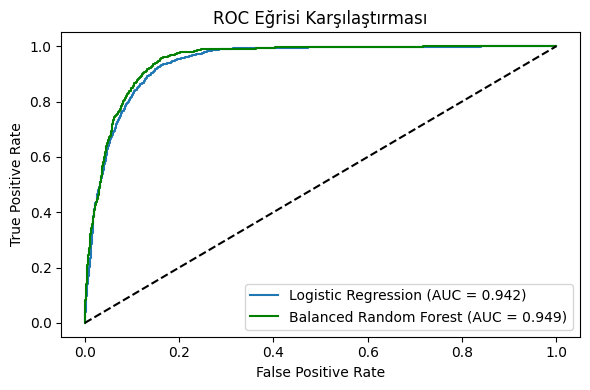

In [7]:
# ROC Eğrisi Grafiği
fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_probs)
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)

plt.figure(figsize=(6, 4))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, lr_probs):.3f})')
plt.plot(fpr_rf, tpr_rf, label=f'Balanced Random Forest (AUC = {roc_auc_score(y_test, rf_probs):.3f})', color='green')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Eğrisi Karşılaştırması')
plt.legend()
plt.tight_layout()
plt.show()

## 5. Modeli Kaydetme (MLOps İçin)

In [8]:
# En iyi modeli kaydediyoruz
joblib.dump(rf_pipe, 'model.joblib')
print('model.joblib başarıyla kaydedildi!')

model.joblib başarıyla kaydedildi!


In [9]:
# Modeli yükleyip test edelim
model = joblib.load('model.joblib')
ornek_musteri = X_test.iloc[0:1]
tahmin_olasilik = model.predict_proba(ornek_musteri)[0][1]
tahmin = 1 if tahmin_olasilik >= best_threshold else 0

print('Örnek müşteri için tahmin:', 'Abone Olur' if tahmin == 1 else 'Abone Olmaz')
print(f'Olasılık: {tahmin_olasilik:.2%}')

Örnek müşteri için tahmin: Abone Olmaz
Olasılık: 11.90%
